In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold

DataSet = "D:/DiabetesMellitus/DataSet/diabetes_dataset.csv"


Categories = ['age' ,	'gender' ,	'ethnicity'	, 'education_level'	, 'income_level'   ,	'employment_status'	, 'smoking_status'	,
               'alcohol_consumption_per_week'	, 'physical_activity_minutes_per_week'	, 'diet_score'	, 'sleep_hours_per_day'	,
                 'screen_time_hours_per_day'	, 'family_history_diabetes'	, 'hypertension_history'	, 'cardiovascular_history'	,
                   'bmi'	, 'waist_to_hip_ratio'	, 'systolic_bp'	, 'diastolic_bp'	, 'heart_rate'	, 'cholesterol_total'	,
                     'hdl_cholesterol'	, 'ldl_cholesterol'	, 'triglycerides'	, 'glucose_fasting'	, 'glucose_postprandial'	,
                       'insulin_level'	, 'hba1c'	, 'diabetes_risk_score'	, 'diabetes_stage'	, 'diagnosed_diabetes'

]

df = pd.read_csv(DataSet, names=Categories , header=0)

print("Dataset:")
print(df.head())
print("\nDataset Shape:", df.shape)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
df['Fold'] = -1

for fold, (train_idx, val_idx) in enumerate(skf.split(df, df['diagnosed_diabetes'])):
    df.loc[val_idx, 'Fold'] = fold

print("\nDistribution across 5 categories:")
print(df['Fold'].value_counts().sort_index())

Dataset:
   age  gender ethnicity education_level  income_level employment_status  \
0   58    Male     Asian      Highschool  Lower-Middle          Employed   
1   48  Female     White      Highschool        Middle          Employed   
2   60    Male  Hispanic      Highschool        Middle        Unemployed   
3   74  Female     Black      Highschool           Low           Retired   
4   46    Male     White        Graduate        Middle           Retired   

  smoking_status  alcohol_consumption_per_week  \
0          Never                             0   
1         Former                             1   
2          Never                             1   
3          Never                             0   
4          Never                             1   

   physical_activity_minutes_per_week  diet_score  ...  hdl_cholesterol  \
0                                 215         5.7  ...               41   
1                                 143         6.7  ...               55   
2       

In [ ]:
num_cols = df.select_dtypes(include=[np.number]).columns.drop(['diagnosed_diabetes', 'Fold'], errors='ignore')

clinical_cols = ['glucose_fasting', 'glucose_postprandial', 'insulin_level', 'bmi', 'systolic_bp', 'diastolic_bp']
for col in clinical_cols:
    if col in df.columns:
        df[col] = df[col].apply(lambda x: np.nan if x <= 0 else x)

for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df.groupby('diagnosed_diabetes')[col].transform(lambda x: x.fillna(x.median()))

cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
if 'diabetes_stage' in cat_cols:
    cat_cols.remove('diabetes_stage')

df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

print("Preprocessed Shape:", df_encoded.shape)
print ("Done Preprocessing")

Preprocessed Shape: (100000, 44)
Done Preprocessing


C:\Users\fares\AppData\Local\Temp\ipykernel_8520\2594032537.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

drop_cols = ['diagnosed_diabetes', 'Fold', 'diabetes_stage']
X = df_encoded.drop(columns=[c for c in drop_cols if c in df_encoded.columns]).values
y = df_encoded['diagnosed_diabetes'].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

minmax_scaler = MinMaxScaler()
X_train_minmax = minmax_scaler.fit_transform(X_train)
X_test_minmax = minmax_scaler.transform(X_test)

std_scaler = StandardScaler()
X_train_std = std_scaler.fit_transform(X_train)
X_test_std = std_scaler.transform(X_test)

print(f"Train Shape: {X_train.shape}, Test Shape: {X_test.shape}")
print(f"MinMax Feature Bounds: [{X_train_minmax.min():.2f}, {X_train_minmax.max():.2f}]")
print(f"Standardized Feature Mean: {X_train_std.mean():.2f}, Std: {X_train_std.std():.2f}")

Train Shape: (80000, 41), Test Shape: (20000, 41)
MinMax Feature Bounds: [0.00, 1.00]
Standardized Feature Mean: 0.00, Std: 1.00


In [12]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization

input_dim = X_train.shape[1]

def create_shallow_mlp(input_shape):
    model = Sequential([
        tf.keras.Input(shape=(input_shape,)),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ], name="Shallow_MLP")
    return model

def create_deep_mlp(input_shape):
    model = Sequential([
        tf.keras.Input(shape=(input_shape,)),
        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ], name="Deep_MLP")
    return model

def create_wide_mlp(input_shape):
    model = Sequential([
        tf.keras.Input(shape=(input_shape,)),
        Dense(256, activation='relu'),
        Dropout(0.4),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ], name="Wide_MLP")
    return model

shallow_model = create_shallow_mlp(input_dim)
deep_model = create_deep_mlp(input_dim)
wide_model = create_wide_mlp(input_dim)


In [13]:
from tensorflow.keras.optimizers import Adam, SGD

experiments_config = [
    {
        "name": "Exp 1: Shallow MLP (MinMax + Adam)",
        "model": create_shallow_mlp(input_dim),
        "X_tr": X_train_minmax, "X_te": X_test_minmax,
        "optimizer": Adam(learning_rate=0.001),
        "epochs": 50, "batch_size": 32
    },
    {
        "name": "Exp 2: Deep MLP (Standardized + Adam)",
        "model": create_deep_mlp(input_dim),
        "X_tr": X_train_std, "X_te": X_test_std,
        "optimizer": Adam(learning_rate=0.001),
        "epochs": 50, "batch_size": 32
    },
    {
        "name": "Exp 3: Wide MLP (Standardized + SGD)",
        "model": create_wide_mlp(input_dim),
        "X_tr": X_train_std, "X_te": X_test_std,
        "optimizer": SGD(learning_rate=0.01, momentum=0.9),
        "epochs": 50, "batch_size": 32
    }
]

histories = {}
fitted_models = {}

for exp in experiments_config:
    print(f"\nTraining {exp['name']}...")
    model = exp["model"]
    model.compile(
        optimizer=exp["optimizer"],
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    
    history = model.fit(
        exp["X_tr"], y_train,
        validation_data=(exp["X_te"], y_test),
        epochs=exp["epochs"],
        batch_size=exp["batch_size"],
        verbose=0
    )
    
    histories[exp["name"]] = history
    fitted_models[exp["name"]] = (model, exp["X_te"])
    print(f"Finished {exp['name']} | Best Val Accuracy: {max(history.history['val_accuracy']):.4f}")


Training Exp 1: Shallow MLP (MinMax + Adam)...
Finished Exp 1: Shallow MLP (MinMax + Adam) | Best Val Accuracy: 0.9100

Training Exp 2: Deep MLP (Standardized + Adam)...
Finished Exp 2: Deep MLP (Standardized + Adam) | Best Val Accuracy: 0.9165

Training Exp 3: Wide MLP (Standardized + SGD)...
Finished Exp 3: Wide MLP (Standardized + SGD) | Best Val Accuracy: 0.9144


In [14]:
comparison_results = []

for exp_name, (model, X_te) in fitted_models.items():
    loss, accuracy = model.evaluate(X_te, y_test, verbose=0)
    history = histories[exp_name]
    
    comparison_results.append({
        "Experiment Name": exp_name,
        "Train Accuracy (%)": round(history.history['accuracy'][-1] * 100, 2),
        "Val Accuracy (%)": round(accuracy * 100, 2),
        "Train Loss": round(history.history['loss'][-1], 4),
        "Val Loss": round(loss, 4)
    })

df_results = pd.DataFrame(comparison_results).sort_values(by="Val Accuracy (%)", ascending=False)
print("=== Experimentation Results Comparison ===")
print(df_results.to_string(index=False))

=== Experimentation Results Comparison ===
                      Experiment Name  Train Accuracy (%)  Val Accuracy (%)  Train Loss  Val Loss
Exp 2: Deep MLP (Standardized + Adam)               91.61             91.56      0.2173    0.2258
 Exp 3: Wide MLP (Standardized + SGD)               91.66             91.44      0.2128    0.2266
   Exp 1: Shallow MLP (MinMax + Adam)               91.09             90.86      0.2265    0.2357


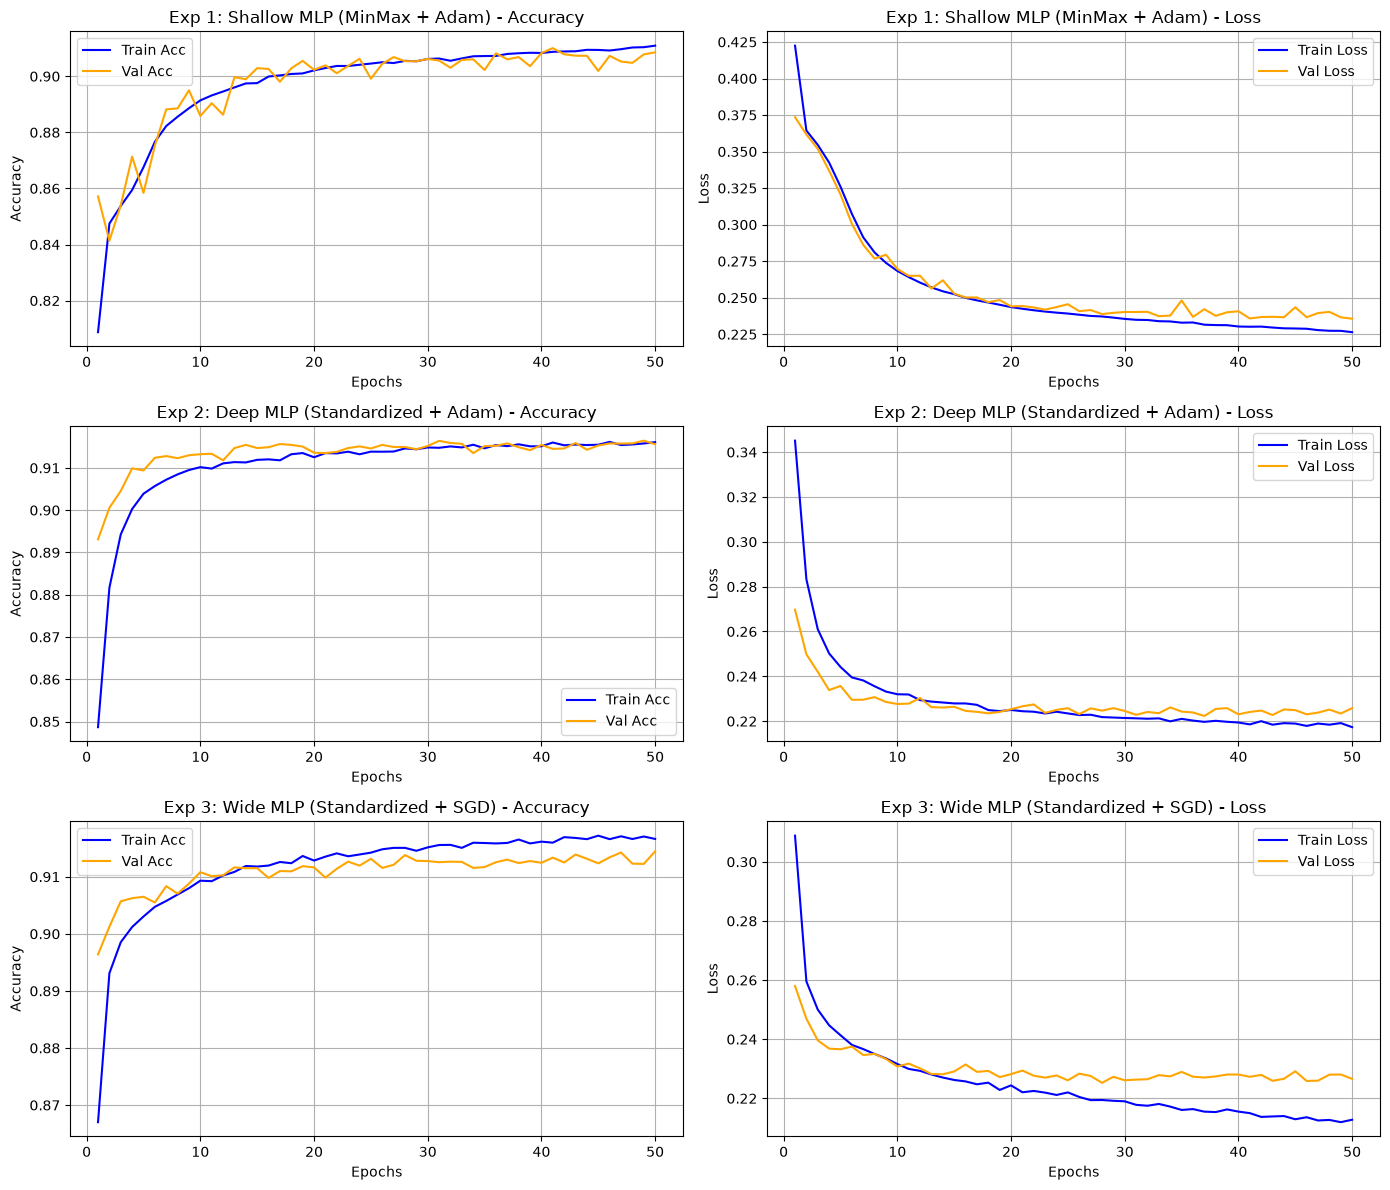

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(histories), 2, figsize=(14, 12))

for idx, (exp_name, history) in enumerate(histories.items()):
    epochs = range(1, len(history.history['accuracy']) + 1)
    
    axes[idx, 0].plot(epochs, history.history['accuracy'], label='Train Acc', color='blue')
    axes[idx, 0].plot(epochs, history.history['val_accuracy'], label='Val Acc', color='orange')
    axes[idx, 0].set_title(f"{exp_name} - Accuracy")
    axes[idx, 0].set_xlabel('Epochs')
    axes[idx, 0].set_ylabel('Accuracy')
    axes[idx, 0].legend()
    axes[idx, 0].grid(True)
    
    axes[idx, 1].plot(epochs, history.history['loss'], label='Train Loss', color='blue')
    axes[idx, 1].plot(epochs, history.history['val_loss'], label='Val Loss', color='orange')
    axes[idx, 1].set_title(f"{exp_name} - Loss")
    axes[idx, 1].set_xlabel('Epochs')
    axes[idx, 1].set_ylabel('Loss')
    axes[idx, 1].legend()
    axes[idx, 1].grid(True)

plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import classification_report, confusion_matrix

for exp_name, (model, X_te) in fitted_models.items():
    print("=" * 65)
    print(f" Classification Report: {exp_name}")
    print("=" * 65)
    
    y_pred_probs = model.predict(X_te, verbose=0)
    y_pred = (y_pred_probs > 0.5).astype(int).flatten()
    
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:")
    print(f"TN: {cm[0][0]} | FP: {cm[0][1]}")
    print(f"FN: {cm[1][0]} | TP: {cm[1][1]}\n")
    
    print(classification_report(y_test, y_pred, target_names=['No Diabetes (0)', 'Diabetes (1)']))
    print("\n")

 Classification Report: Exp 1: Shallow MLP (MinMax + Adam)
Confusion Matrix:
TN: 7772 | FP: 228
FN: 1601 | TP: 10399

                 precision    recall  f1-score   support

No Diabetes (0)       0.83      0.97      0.89      8000
   Diabetes (1)       0.98      0.87      0.92     12000

       accuracy                           0.91     20000
      macro avg       0.90      0.92      0.91     20000
   weighted avg       0.92      0.91      0.91     20000



 Classification Report: Exp 2: Deep MLP (Standardized + Adam)
Confusion Matrix:
TN: 7939 | FP: 61
FN: 1627 | TP: 10373

                 precision    recall  f1-score   support

No Diabetes (0)       0.83      0.99      0.90      8000
   Diabetes (1)       0.99      0.86      0.92     12000

       accuracy                           0.92     20000
      macro avg       0.91      0.93      0.91     20000
   weighted avg       0.93      0.92      0.92     20000



 Classification Report: Exp 3: Wide MLP (Standardized + SGD)
Confusi